# Social Media Usage Analysis – Data Analyst Project
**Author:** Ishant Jaiswal | **Admission No.:** 2026B01011006 | **Tools:** Python, pandas, matplotlib, seaborn

## 1. Business problem
A digital-wellbeing team wants to understand **how people use social media** and **which usage patterns hurt sleep and studies**, so that awareness campaigns can target the right groups.

**Questions we will answer**
1. What is the overall social media usage pattern of the respondents?
2. Which platforms and purposes are most common?
3. Do usage hours, sessions and posts move together?
4. Does usage differ by age group, occupation, gender or day type?
5. How does heavy usage affect sleep and studies, and who is at high risk?

## 2. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi']=100

## 3. Load and inspect the data

In [2]:
df = pd.read_excel('../data/raw/Raw_Social_Media_Usage_Dataset.xlsx')
print('Rows, Columns:', df.shape)
df.head()

Rows, Columns: (250, 16)


  Participant ID       Age      Gender     Occupation Most Used Platform  Primary Purpose   Day Type Daily Usage Hours Sessions Per Day Preferred Usage Time Notifications Setting Private Account Posts Per Week    Effect on Sleep     Effect on Studies Data Usage
0           P959        16  Non-binary        Student                NaN   entertainment        Both               2.7               24           Late Night                    On              No             20          No effect             No effect       HIGH
1           P129  36 years         NaN  Self-employed             Reddit        EDUCATION   WEEKEND                1.7               35          late night                Enabled             NO               5         no effect   SLIGHTLY DISTRACTING       HIGH
2           P943        40      Female       EMPLOYED                  X        EDUCATION    Weekend               6.4               32              Morning              Disabled             yes             17    H

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Participant ID         250 non-null    str   
 1   Age                    250 non-null    object
 2   Gender                 225 non-null    str   
 3   Occupation             250 non-null    str   
 4   Most Used Platform     213 non-null    str   
 5   Primary Purpose        250 non-null    str   
 6   Day Type               250 non-null    str   
 7   Daily Usage Hours      250 non-null    object
 8   Sessions Per Day       249 non-null    object
 9   Preferred Usage Time   250 non-null    str   
 10  Notifications Setting  250 non-null    str   
 11  Private Account        250 non-null    str   
 12  Posts Per Week         249 non-null    object
 13  Effect on Sleep        250 non-null    str   
 14  Effect on Studies      250 non-null    str   
 15  Data Usage             250 non-nul

In [4]:
print('Missing values per column:'); print(df.isna().sum()[df.isna().sum()>0])
print('\nExact duplicate rows:', df.duplicated().sum())
print('Participant IDs that appear more than once:', df['Participant ID'].duplicated().sum())
for c in ['Age','Daily Usage Hours','Sessions Per Day','Posts Per Week']:
    print(f"{c}: {df[c].astype(str).str.contains('[a-zA-Z]').sum()} entries contain text such as 'years', 'hrs'")
print('\nGender values:', df['Gender'].dropna().unique().tolist())
print('Notifications values:', df['Notifications Setting'].unique().tolist())

Missing values per column:
Gender                25
Most Used Platform    37
Sessions Per Day       1
Posts Per Week         1
dtype: int64

Exact duplicate rows: 2
Participant IDs that appear more than once: 30
Age: 50 entries contain text such as 'years', 'hrs'
Daily Usage Hours: 46 entries contain text such as 'years', 'hrs'
Sessions Per Day: 59 entries contain text such as 'years', 'hrs'
Posts Per Week: 55 entries contain text such as 'years', 'hrs'

Gender values: ['Non-binary', 'Female', ' female ', 'MALE', 'Male', 'Prefer not to say']
Notifications values: ['On', 'Enabled', 'Disabled', 'Off', ' off ', 'ON']


**What we found:**
- Numeric columns stored as text (`36 years`, `1.7 hrs`, `13 sessions`, `6 posts`).
- Inconsistent text: extra spaces and mixed case (` female `, `MALE`, `YOUTUBE`).
- The same idea written two ways: `On`/`Enabled`, `Off`/`Disabled`, `Yes`/`Private`, `No`/`Public`.
- Missing values in `Gender`, `Most Used Platform`, `Sessions Per Day` and `Posts Per Week`.
- 2 exact duplicate rows.
- Some Participant IDs repeat but belong to *different* people (different age, platform, etc.), so they are kept – only exact duplicate rows are removed.

## 4. Clean the data

In [5]:
clean = df.copy()

# 1. Remove leading/trailing spaces from every column (and keep missing values as NaN)
for c in clean.columns:
    clean[c] = clean[c].astype(str).str.strip().replace('nan', np.nan)

# 2. Convert text-numbers to real numbers ('36 years' -> 36, '1.7 hrs' -> 1.7)
for c, unit in [('Age','years'),('Daily Usage Hours','hrs'),('Sessions Per Day','sessions'),('Posts Per Week','posts')]:
    clean[c] = pd.to_numeric(clean[c].str.replace(unit,'',regex=False).str.strip(), errors='coerce')

# 3. Standardise text to Title Case
text_cols = ['Gender','Occupation','Most Used Platform','Primary Purpose','Day Type','Preferred Usage Time',
             'Notifications Setting','Private Account','Effect on Sleep','Effect on Studies','Data Usage']
for c in text_cols:
    clean[c] = clean[c].str.title()
clean['Most Used Platform'] = clean['Most Used Platform'].replace({'Youtube':'YouTube','Whatsapp':'WhatsApp'})

# 4. Merge labels that mean the same thing
clean['Notifications Setting'] = clean['Notifications Setting'].replace({'Enabled':'On','Disabled':'Off'})
clean['Private Account'] = clean['Private Account'].replace({'Private':'Yes','Public':'No'})

# 5. Missing categories -> 'Unknown'; missing numbers -> median
clean['Gender'] = clean['Gender'].fillna('Unknown')
clean['Most Used Platform'] = clean['Most Used Platform'].fillna('Unknown')
for c in ['Sessions Per Day','Posts Per Week']:
    clean[c] = clean[c].fillna(clean[c].median())
clean[['Age','Sessions Per Day','Posts Per Week']] = clean[['Age','Sessions Per Day','Posts Per Week']].astype(int)

# 6. Remove exact duplicate rows
clean = clean.drop_duplicates().reset_index(drop=True)
print('Rows after cleaning:', len(clean), '| Missing values left:', clean.isna().sum().sum())

Rows after cleaning: 248 | Missing values left: 0


## 5. Create new columns (feature engineering)

In [6]:
def usage_level(h):
    if h < 2: return 'Light (<2h)'
    if h < 4: return 'Moderate (2-4h)'
    if h < 7: return 'Heavy (4-7h)'
    return 'Extreme (7h+)'
clean['Usage_Level'] = clean['Daily Usage Hours'].apply(usage_level)
clean['Age_Group'] = pd.cut(clean['Age'], [15,20,25,30,35,45], labels=['16-20','21-25','26-30','31-35','36-45'])

# Turn the 'effect' answers into scores so we can calculate correlations
sleep_map = {'No Effect':0,'Slightly Affected':1,'Moderately Affected':2,'Highly Affected':3}
study_map = {'Improves Focus':-1,'No Effect':0,'Slightly Distracting':1,'Highly Distracting':2}
clean['Sleep_Impact_Score'] = clean['Effect on Sleep'].map(sleep_map)
clean['Study_Impact_Score'] = clean['Effect on Studies'].map(study_map)

# High Risk = uses 7h+ a day AND (sleep moderately/highly affected OR studies highly distracted)
clean['High_Risk'] = ((clean['Daily Usage Hours']>=7) &
                      ((clean['Sleep_Impact_Score']>=2) | (clean['Study_Impact_Score']==2)))
clean[['Participant ID','Daily Usage Hours','Usage_Level','Age_Group','High_Risk']].head()

  Participant ID  Daily Usage Hours      Usage_Level Age_Group  High_Risk
0           P959                2.7  Moderate (2-4h)     16-20      False
1           P129                1.7      Light (<2h)     36-45      False
2           P943                6.4     Heavy (4-7h)     36-45      False
3           P793                1.7      Light (<2h)     31-35      False
4           P771                7.1    Extreme (7h+)     36-45      False

## 6. Exploratory data analysis (EDA)
### Q1. Overall usage pattern

count    248.00
mean       4.94
std        2.78
min        0.60
25%        2.70
50%        4.55
75%        7.22
max       10.00
Name: Daily Usage Hours, dtype: float64


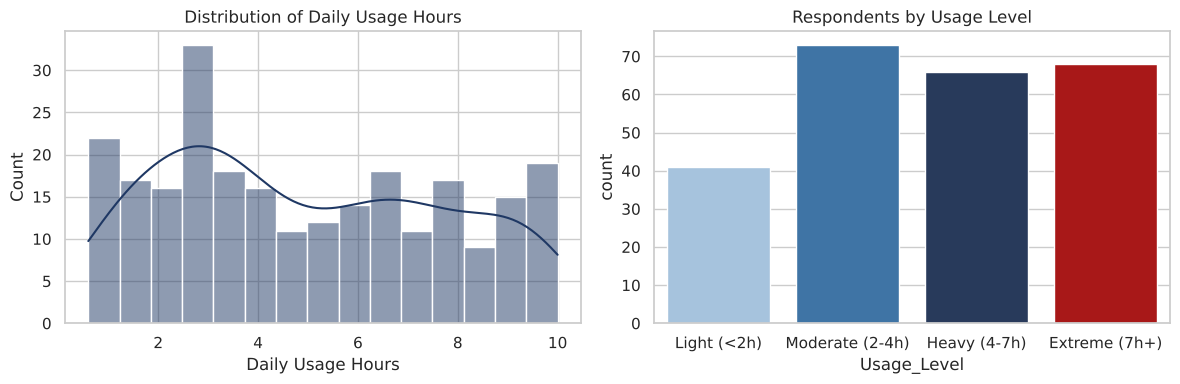

In [7]:
print(clean['Daily Usage Hours'].describe().round(2))
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.histplot(clean['Daily Usage Hours'],bins=15,kde=True,color='#1F3864',ax=ax[0]);ax[0].set_title('Distribution of Daily Usage Hours')
order=['Light (<2h)','Moderate (2-4h)','Heavy (4-7h)','Extreme (7h+)']
sns.countplot(data=clean,x='Usage_Level',hue='Usage_Level',legend=False,order=order,palette=dict(zip(order,['#9DC3E6','#2E75B6','#1F3864','#C00000'])),ax=ax[1]);ax[1].set_title('Respondents by Usage Level')
plt.tight_layout();plt.savefig('../images/01_overall_usage.png');plt.show()

### Q2. Which platforms and purposes are most common?

Most Used Platform
Snapchat     5.78
X            5.47
YouTube      5.12
Instagram    5.06
Reddit       4.99
Pinterest    4.88
WhatsApp     4.61
Facebook     4.42
Name: Daily Usage Hours, dtype: float64


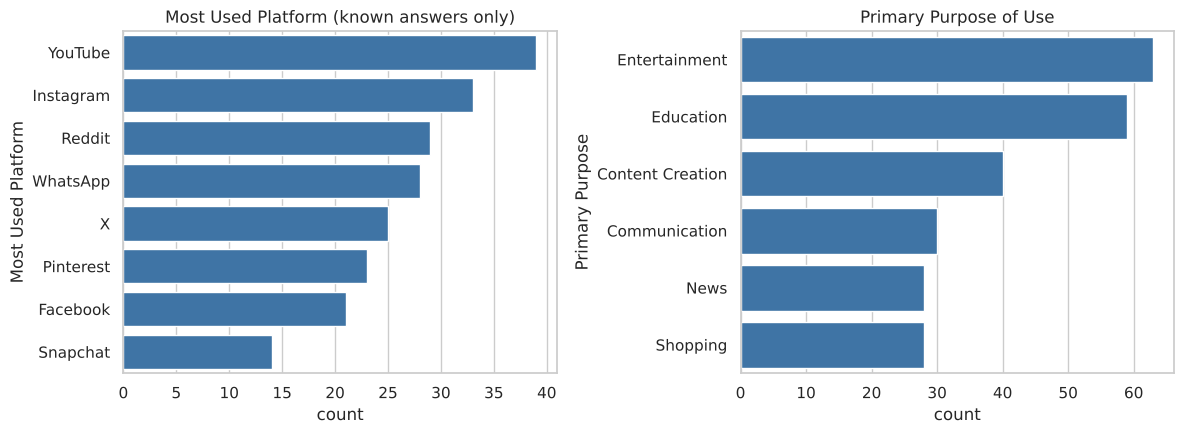

In [8]:
known = clean[clean['Most Used Platform']!='Unknown']
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
sns.countplot(data=known,y='Most Used Platform',order=known['Most Used Platform'].value_counts().index,color='#2E75B6',ax=ax[0]);ax[0].set_title('Most Used Platform (known answers only)')
sns.countplot(data=clean,y='Primary Purpose',order=clean['Primary Purpose'].value_counts().index,color='#2E75B6',ax=ax[1]);ax[1].set_title('Primary Purpose of Use')
plt.tight_layout();plt.savefig('../images/02_platform_purpose.png');plt.show()
print(known.groupby('Most Used Platform')['Daily Usage Hours'].mean().round(2).sort_values(ascending=False))

### Q3. Do usage hours, sessions and posts move together?

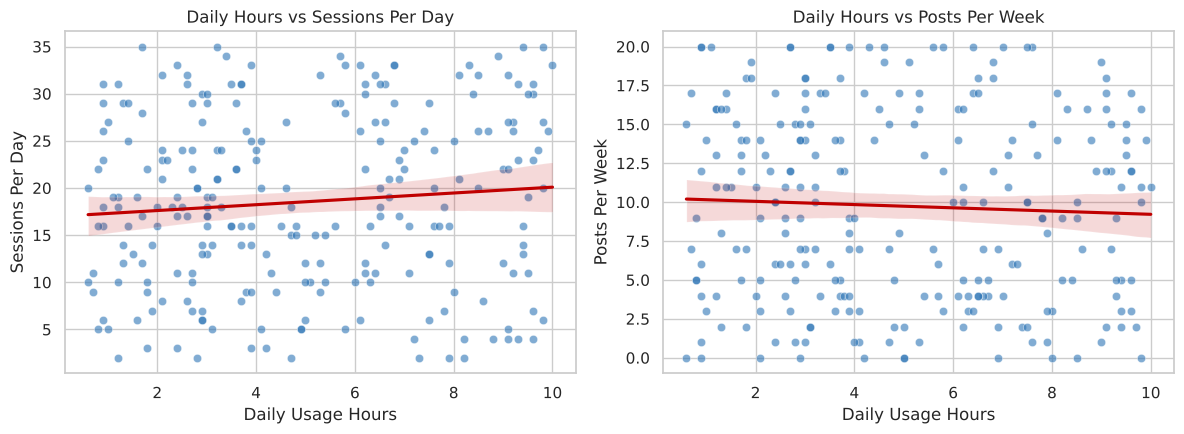

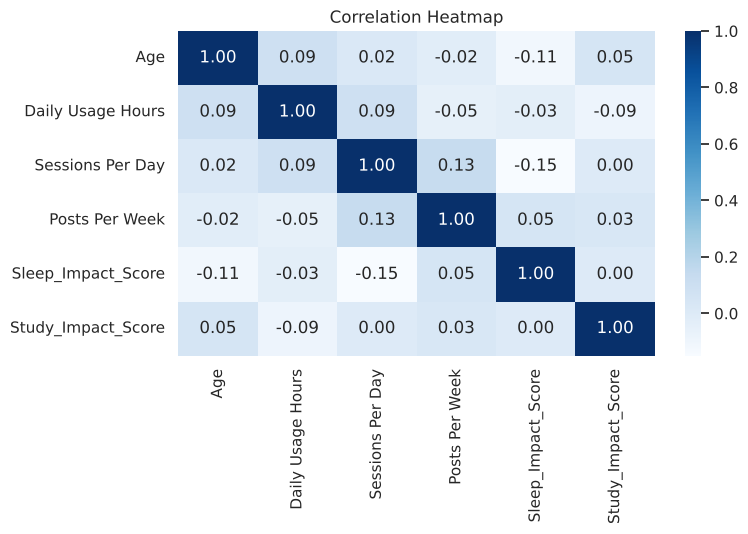

In [9]:
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
sns.scatterplot(data=clean,x='Daily Usage Hours',y='Sessions Per Day',alpha=.6,color='#2E75B6',ax=ax[0])
sns.regplot(data=clean,x='Daily Usage Hours',y='Sessions Per Day',scatter=False,color='#C00000',ax=ax[0]);ax[0].set_title('Daily Hours vs Sessions Per Day')
sns.scatterplot(data=clean,x='Daily Usage Hours',y='Posts Per Week',alpha=.6,color='#2E75B6',ax=ax[1])
sns.regplot(data=clean,x='Daily Usage Hours',y='Posts Per Week',scatter=False,color='#C00000',ax=ax[1]);ax[1].set_title('Daily Hours vs Posts Per Week')
plt.tight_layout();plt.savefig('../images/03_usage_relationships.png');plt.show()
num_cols = ['Age','Daily Usage Hours','Sessions Per Day','Posts Per Week','Sleep_Impact_Score','Study_Impact_Score']
plt.figure(figsize=(8,5.5))
sns.heatmap(clean[num_cols].corr().round(2),annot=True,cmap='Blues',fmt='.2f');plt.title('Correlation Heatmap')
plt.tight_layout();plt.savefig('../images/04_correlation.png');plt.show()

### Q4. Does usage differ by age group, occupation, gender or day type?

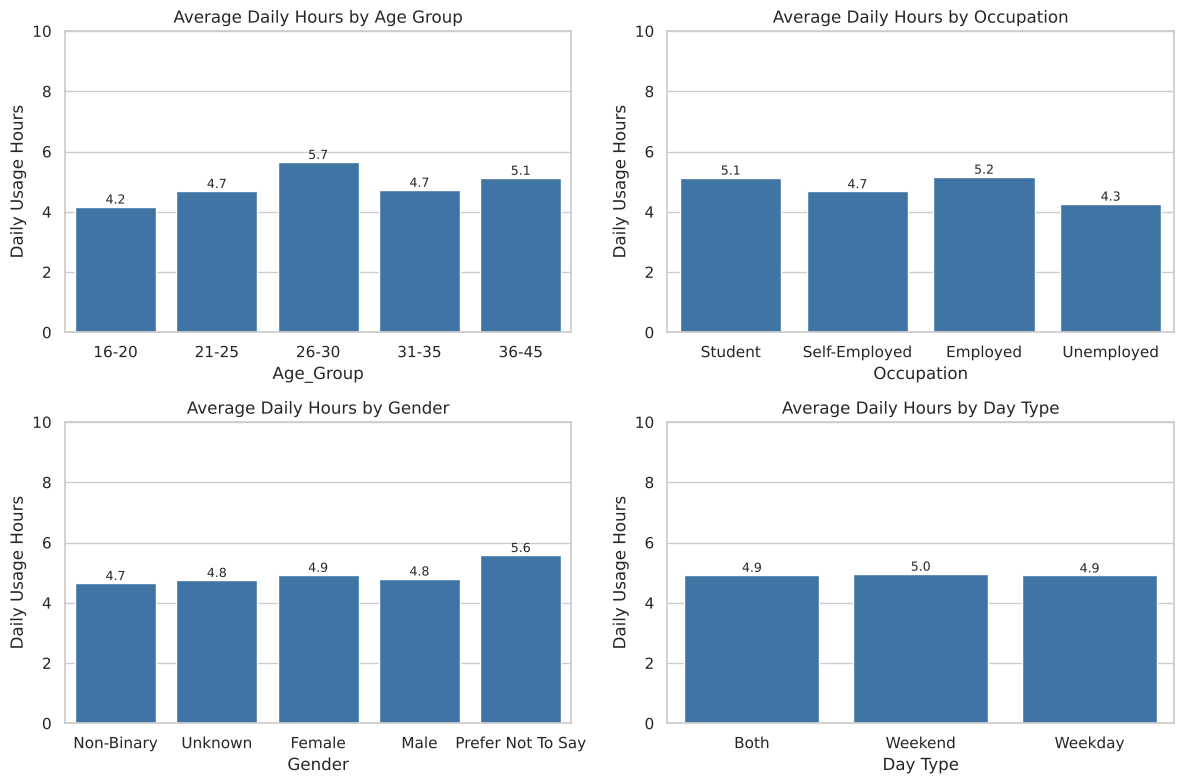

In [10]:
fig,ax=plt.subplots(2,2,figsize=(12,8))
for a,col in zip(ax.flat,['Age_Group','Occupation','Gender','Day Type']):
    sns.barplot(data=clean,x=col,y='Daily Usage Hours',errorbar=None,color='#2E75B6',ax=a)
    a.set_title(f'Average Daily Hours by {col.replace("_"," ")}');a.set_ylim(0,10)
    for p in a.patches:a.annotate(f'{p.get_height():.1f}',(p.get_x()+p.get_width()/2,p.get_height()),ha='center',va='bottom',fontsize=9)
plt.tight_layout();plt.savefig('../images/05_group_comparison.png');plt.show()

### Q5. How does heavy usage affect sleep and studies?

                 Sleep_Impact_Score  Study_Impact_Score
Usage_Level                                            
Light (<2h)                    1.39                0.66
Moderate (2-4h)                1.11                0.58
Heavy (4-7h)                   1.06                0.58
Extreme (7h+)                  1.25                0.46


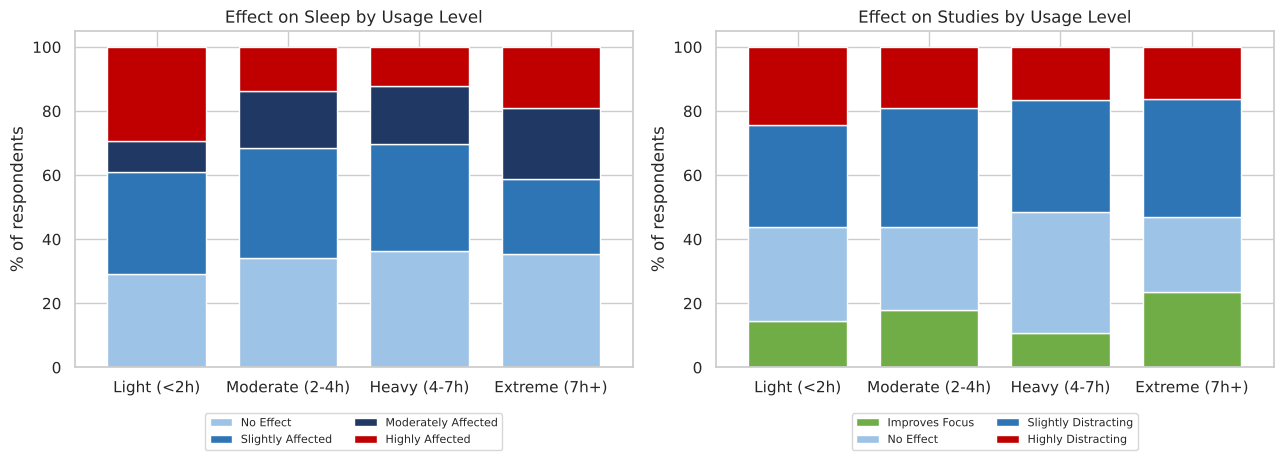

In [11]:
fig,ax=plt.subplots(1,2,figsize=(13,4.8))
sleep_order=['No Effect','Slightly Affected','Moderately Affected','Highly Affected']
study_order=['Improves Focus','No Effect','Slightly Distracting','Highly Distracting']
for a,col,o,pal in [(ax[0],'Effect on Sleep',sleep_order,['#9DC3E6','#2E75B6','#1F3864','#C00000']),
                    (ax[1],'Effect on Studies',study_order,['#70AD47','#9DC3E6','#2E75B6','#C00000'])]:
    pct = pd.crosstab(clean['Usage_Level'],clean[col],normalize='index').reindex(index=order,columns=o)*100
    pct.plot(kind='bar',stacked=True,color=pal,ax=a,width=.75)
    a.set_title(f'{col} by Usage Level');a.set_ylabel('% of respondents');a.set_xlabel('');a.tick_params(axis='x',rotation=0)
    a.legend(fontsize=8,loc='upper center',bbox_to_anchor=(.5,-.12),ncol=2)
plt.tight_layout();plt.savefig('../images/06_impact_sleep_studies.png',bbox_inches='tight');plt.show()
print(clean.groupby('Usage_Level')[['Sleep_Impact_Score','Study_Impact_Score']].mean().reindex(order).round(2))

In [12]:
risk = clean[clean['High_Risk']].sort_values('Daily Usage Hours',ascending=False)
print(f"{len(risk)} respondents ({len(risk)/len(clean):.1%}) are High Risk")
print('Average daily hours of High Risk users:', round(risk['Daily Usage Hours'].mean(),1),'vs overall', round(clean['Daily Usage Hours'].mean(),1))
risk[['Participant ID','Age','Occupation','Most Used Platform','Daily Usage Hours','Effect on Sleep','Effect on Studies']].head(10)

35 respondents (14.1%) are High Risk
Average daily hours of High Risk users: 8.5 vs overall 4.9


    Participant ID  Age     Occupation Most Used Platform  Daily Usage Hours      Effect on Sleep     Effect on Studies
193           P990   27        Student            Unknown                9.9      Highly Affected  Slightly Distracting
74            P783   35        Student           WhatsApp                9.8            No Effect    Highly Distracting
129           P170   17        Student            YouTube                9.6  Moderately Affected    Highly Distracting
139           P922   45  Self-Employed           Snapchat                9.6      Highly Affected        Improves Focus
171           P688   35        Student            YouTube                9.6            No Effect    Highly Distracting
119           P520   34       Employed          Instagram                9.6  Moderately Affected             No Effect
135           P485   41       Employed             Reddit                9.5  Moderately Affected  Slightly Distracting
153           P706   28       Employed  

## 7. Key insights (generated from the data)
The correlations are all close to zero – **more hours does not automatically mean more sessions, more posts, or a worse self-reported effect** in this dataset.

In [13]:
r_s=clean['Daily Usage Hours'].corr(clean['Sessions Per Day']); r_p=clean['Daily Usage Hours'].corr(clean['Posts Per Week'])
r_sl=clean['Daily Usage Hours'].corr(clean['Sleep_Impact_Score']); r_st=clean['Daily Usage Hours'].corr(clean['Study_Impact_Score'])
top_plat=known['Most Used Platform'].value_counts().idxmax(); top_pur=clean['Primary Purpose'].value_counts().idxmax()
by_occ=clean.groupby('Occupation')['Daily Usage Hours'].mean(); by_age=clean.groupby('Age_Group',observed=True)['Daily Usage Hours'].mean()
heavy_share=(clean['Daily Usage Hours']>=4).mean()
print(f"1. Average use is {clean['Daily Usage Hours'].mean():.1f} hours/day (median {clean['Daily Usage Hours'].median():.1f}); {heavy_share:.0%} use 4+ hours a day.")
print(f"2. Most used platform: {top_plat}; most common purpose: {top_pur}.")
print(f"3. Hours vs sessions r = {r_s:.2f}; hours vs posts r = {r_p:.2f}; hours vs sleep impact r = {r_sl:.2f}; hours vs study impact r = {r_st:.2f}.")
print(f"4. Highest-use occupation: {by_occ.idxmax()} ({by_occ.max():.1f}h); lowest: {by_occ.idxmin()} ({by_occ.min():.1f}h).")
print(f"5. Highest-use age group: {by_age.idxmax()} ({by_age.max():.1f}h); lowest: {by_age.idxmin()} ({by_age.min():.1f}h).")
print(f"6. {len(risk)} respondents ({len(risk)/len(clean):.0%}) are High Risk (7h+ a day with strong sleep or study impact).")

1. Average use is 4.9 hours/day (median 4.5); 54% use 4+ hours a day.
2. Most used platform: YouTube; most common purpose: Entertainment.
3. Hours vs sessions r = 0.09; hours vs posts r = -0.05; hours vs sleep impact r = -0.03; hours vs study impact r = -0.09.
4. Highest-use occupation: Employed (5.2h); lowest: Unemployed (4.3h).
5. Highest-use age group: 26-30 (5.7h); lowest: 16-20 (4.2h).
6. 35 respondents (14%) are High Risk (7h+ a day with strong sleep or study impact).


## 8. Recommendations
- Target awareness sessions at the **54% of respondents who use 4+ hours a day**, with extra focus on the 26-30 age group and employed respondents, who have the highest average hours.
- Encourage **screen-free late-night routines** – late night is one of the two most common usage times.
- Offer **screen-time limits and notification control** tips to the High Risk group (7h+ a day with strong sleep or study impact).
- Collect **objective data** (phone screen-time logs, sleep tracker) in the next survey, because self-reported effects showed no clear link with hours used.

> **Remember:** correlation does not prove causation. Effects on sleep and studies are **self-reported**, and in this dataset usage hours show almost no linear relationship with sessions, posts or reported impact (all |r| < 0.1). The analysis shows association, not cause.

## 9. Save the cleaned data

In [14]:
clean.to_csv('../data/processed/social_media_usage_clean.csv',index=False)
print('Saved cleaned file with', len(clean), 'rows and', clean.shape[1], 'columns')

Saved cleaned file with 248 rows and 21 columns
